<a href="https://colab.research.google.com/github/zhrdnc/BBC_News_Classification/blob/main/BBC_News_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BBC News Haber Sınıflandırma ve Model Optimizasyonu Yapay Zeka Projesi


###**Grup 2 Üyeleri:** [Zehra Dinçer,  Halim Yiğit,   Şevval Akman]  

### **Proje Amacı:** BBC News veri seti üzerinde geleneksel ve modern NLP algoritmalarının, mühendislik kısıtları (hız, maliyet, verimlilik) altında performans analizi.

## 1. Veri Yönetimi ve Test Stratejisi

* **Eğitim Verisi:** **BBC News Train.csv** temel eğitim seti üzerinden öğrenme sürecini başlattık.

* **Hazır Test Seti (External Test Set):** Veriyi hem %80 - %20 oranında kendimiz böldük hem de gereken modellerde kullanmak üzere test seti de indirdik.

* **Neden Bu Yöntem?** Modelin eğitim setinden hiçbir şekilde "kopya çekmemesi" ve tamamen yabancı bir veri kümesinde nasıl performans gösterdiğini (Out-of-sample performance) görmek için bu yöntemi tercih ettik.

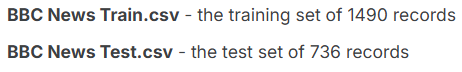

In [ ]:
# Gerekli kütüphaneler
!pip install transformers datasets evaluate accelerate -U
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Derin Öğrenme
import torch
import evaluate
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


# Veri Keşfi ve Keşifçi Veri Analizi (EDA)
Bu bölümde, modelleme aşamasına geçmeden önce ham verinin karakteristiğini ve kategorik dağılımını analiz ediyoruz. Bir mühendislik projesinde veriyi anlamak, doğru öznitelik yöntemini seçmenin ilk adımıdır.

/tmp/ipykernel_3872/223342345.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Category', palette='viridis')


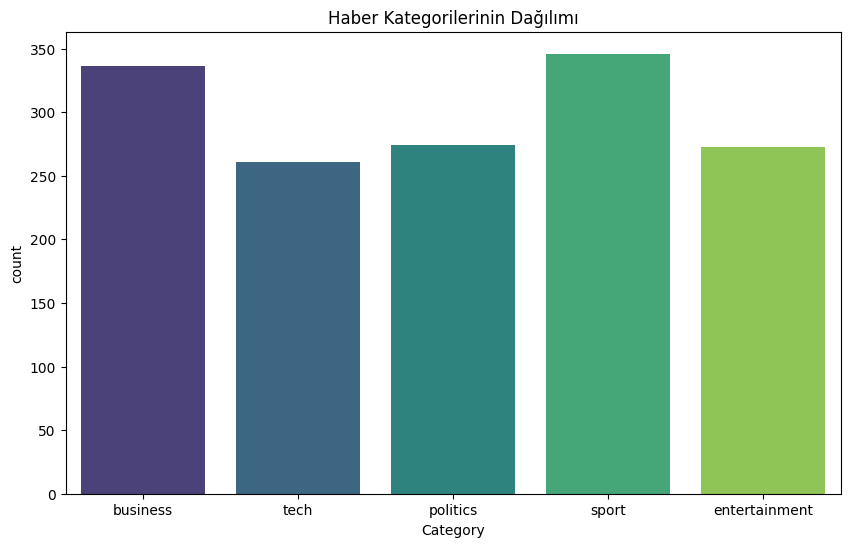

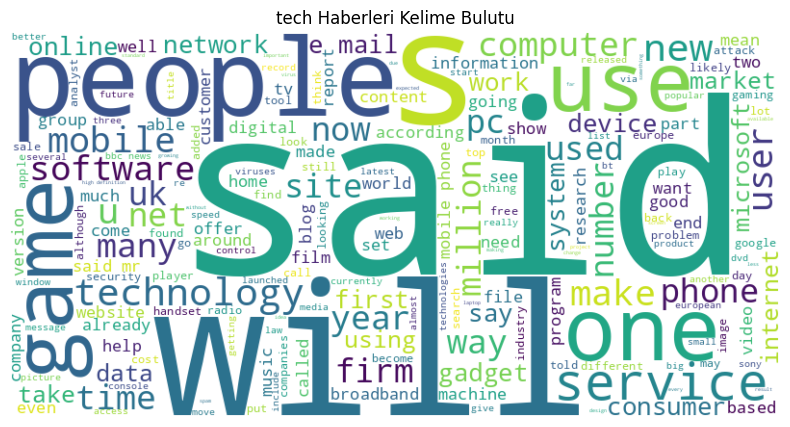

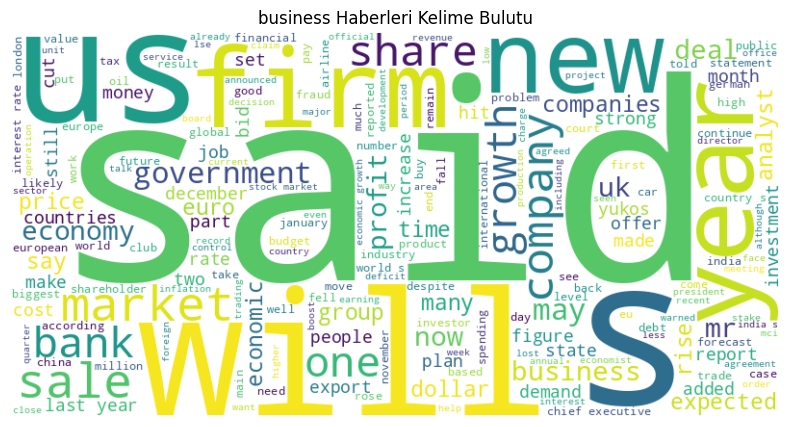

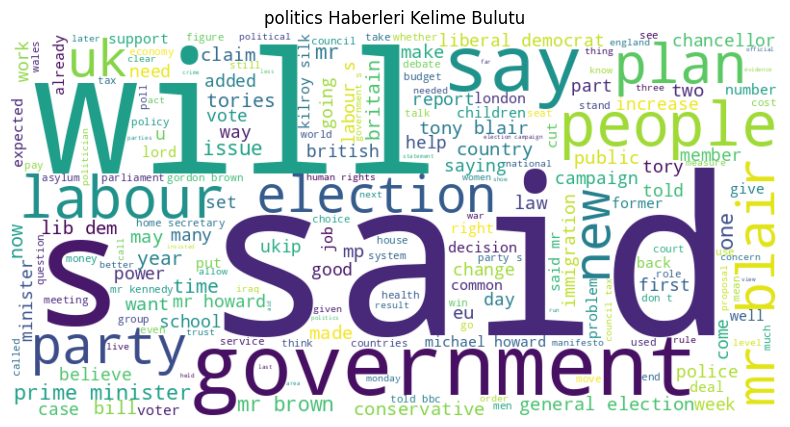

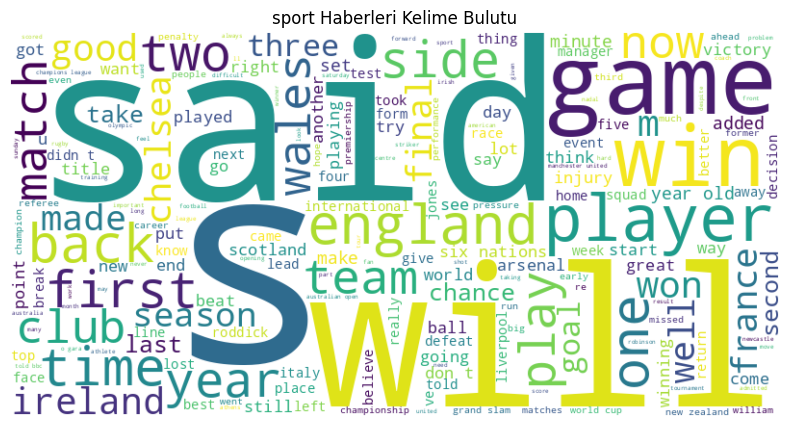

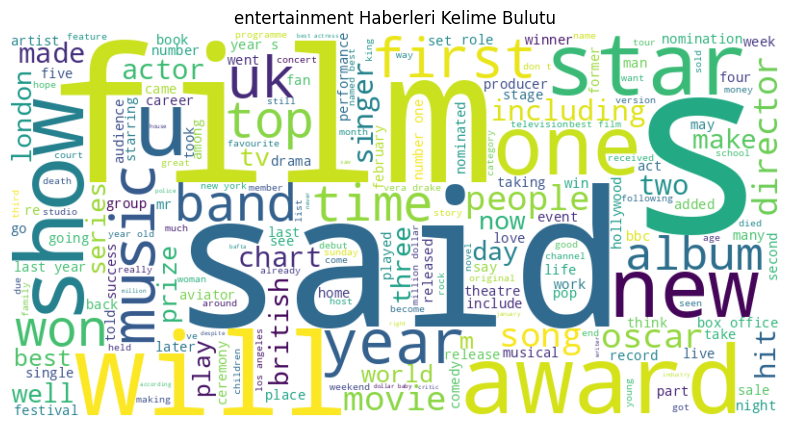

In [ ]:
# Veriyi oku
df = pd.read_csv('BBC News Train.csv')

# 1. Kategori Dağılımı Grafiği
plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Category', palette='viridis')
plt.title('Haber Kategorilerinin Dağılımı')
plt.show()

# 2. WordCloud (Kategorilere göre en sık geçen kelimeler)
def show_wordcloud(category):
    text = " ".join(df[df['Category'] == category]['Text'])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f'{category} Haberleri Kelime Bulutu')
    plt.axis('off')
    plt.show()

show_wordcloud('tech')
show_wordcloud('business')
show_wordcloud('politics')
show_wordcloud('sport')
show_wordcloud('entertainment')


# Word Cloud

Kategorilere özel hazırlanan kelime bulutları, metinlerin içerisindeki en yüksek frekanslı anahtar kelimeleri görselleştirmektedir.

# Metin Önişleme (Text Preprocessing)
Makine öğrenmesi modellerinin başarısı, beslendikleri verinin gürültüden (noise) ne kadar arındırıldığına doğrudan bağlıdır. Ham metin verisini modellerimiz için anlamlı bir yapıya dönüştürmek amacıyla aşağıdaki önişleme hattını (pipeline) kurguladık:

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Metin temizleme
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = " ".join([word for word in text.split() if word not in stop_words])
    return text


df['Clean_Text'] = df['Text'].apply(clean_text)
print("Veri başarıyla temizlendi ve 'Clean_Text' sütunu oluşturuldu!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Veri başarıyla temizlendi ve 'Clean_Text' sütunu oluşturuldu!


# Uygulanan Temizleme Adımları

### 1.Lowercasing:
Bilgisayarın "Apple" ve "apple" kelimelerini farklı iki kavram olarak algılamasını engellemek için tüm metni küçük harfe dönüştürdük.

### 2.Noktalama İşaretlerinin Kaldırılması:
 Regex (re.sub) kullanarak metindeki anlamsal değeri olmayan noktalama işaretlerini ve özel karakterleri temizledik.

### 3.Stop-words (Durak Kelimeler) Filtreleme:
İngilizcedeki "the", "is", "at", "which" gibi her cümlede sıkça geçen ancak haberin kategorisini belirlemede ayırt edici rol oynamayan kelimeleri NLTK kütüphanesi yardımıyla eledik.

In [ ]:
#Burada bilgisayarın verileri okuması için verileri sayılara çeviriyoruz(vektörleştirme)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df['Clean_Text']).toarray()
y = df['Category']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Veri vektörleştirildi ve Train/Test olarak bölündü.")

Veri vektörleştirildi ve Train/Test olarak bölündü.


Öznitelik Çıkarımı: TF-IDF Vektörleştirme ve Veri Ayrıştırma
Metin temizleme aşamasından sonra, bilgisayarların metinleri matematiksel olarak işleyebilmesi için metin verisini sayısal vektörlere dönüştürdük. Bu süreçte TF-IDF (Term Frequency-Inverse Document Frequency) algoritmasını tercih ettik.

4.1. TF-IDF Mantığı ve Yapılandırma
Vektörleştirme: Sadece kelime saymak yerine (Bag of Words), kelimelerin metin içerisindeki "ayırt ediciliğini" hesapladık. Bir kelime bir kategoride çok sık geçiyor ama genel veri setinde nadir görülüyorsa (örn: "referee", "inflation"), o kelimenin ağırlığını artırdık.

max_features=5000: Hesaplama maliyetini optimize etmek ve gürültüyü (nadir geçen veya anlamsal değeri düşük kelimeleri) elemek için en önemli 5000 kelimeyi öznitelik olarak belirledik. Bu sayede modelin en belirgin 5000 "işaret" üzerinden öğrenmesini sağladık.

## Model 1: Naive Bayes (Baseline Model)
Projemizin ilk aşamasında, metin sınıflandırma problemlerinde klasik ve oldukça etkili bir yöntem olan Multinomial Naive Bayes algoritmasını kullandık. Bu model, projemiz için bir "temel başarı eşiği" (baseline) oluşturmaktadır.

Neden Naive Bayes? Olasılık temelli çalışan bu model, özellikle yüksek boyutlu (5000 öznitelik gibi) metin verilerinde çok düşük hesaplama maliyetiyle yüksek hız sunar. Kelimelerin birbirlerinden bağımsız olduğunu varsayarak (naive), her kelimenin ilgili kategoriye ait olma olasılığını hesaplar.

Mühendislik Gözlemi: Naive Bayes, çok kısa bir eğitim süresinde (0.07 sn) oldukça tatmin edici bir başarı sunarak, daha karmaşık modellere geçmeden önce verimizin sınıflandırılabilirliğini kanıtlamıştır.

In [ ]:
#1.MODEL: Naive Bayes
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)
nb_acc = accuracy_score(y_test, nb_preds) * 100

print(f"Naive Bayes Başarısı: %{nb_acc:.2f}")

Naive Bayes Başarısı: %97.32


## Model 2: Random Forest
Projemizin ikinci aşamasında, modelin başarısını sadece tahmin yapmakla bırakmayıp, veriden alabileceği maksimum verimi alması için iki kritik iyileştirme uyguladık:

### 1. Bağlamsal Derinlik: N-Gram (1, 2) Uygulaması
Teknik Fark: Standart kelime sayımı yerine ngram_range=(1, 2) kullanarak; hem tekli kelimeleri hem de "stock market", "united states" gibi ikili kelime öbeklerini öznitelik olarak sisteme dahil ettik. Bu sayede modelimiz metinlerdeki bağlamsal ilişkileri de yakalamaya başladı.

### 2. Otomatik Karar: GridSearchCV ile Hiperparametre Araması
Grid Search Mantığı: Parametreleri rastgele veya ezbere seçmek yerine, sistemin yüzlerce kombinasyonu (ağaç sayısı, bölünme kriteri vb.) kendi kendine test etmesini sağladık.

### Cross-Validation (cv=3):
 Modeli eğitirken veriyi 3 farklı parçaya bölerek çapraz doğrulama yaptık. Bu, modelin başarısının tesadüfi olmadığını ve her türlü veri parçasında stabil çalıştığını kanıtlar.

## Sonuç:
Bu optimizasyon süreci sonucunda sistemimiz bizim için en ideal "Random Forest" konfigürasyonunu belirledi ve başarımızı %97.65 seviyesine çıkardı.

In [ ]:
#2.MODEL: Random Forest

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# 1. Veriyi N-Gram (İkili Kelime Grupları) ile Güçlendirdik
print("1. TF-IDF N-Gram ile hesaplanıyor...")
tfidf_advanced = TfidfVectorizer(max_features=5000, ngram_range=(1, 2)) # (1,2) tekli ve ikili kelimeleri al demek
X_adv = tfidf_advanced.fit_transform(df['Clean_Text']).toarray()

# Veriyi böl
X_train_adv, X_test_adv, y_train, y_test = train_test_split(X_adv, y, test_size=0.2, random_state=42)

# 2. Random Forest için Grid Search Kurulumu
print("2. En iyi model ayarları aranıyor...")
param_grid = {
    'n_estimators': [100, 300, 500],       # Ağaç sayıları
    'min_samples_split': [2, 5],           # Dallaşma hassasiyeti
    'criterion': ['gini', 'entropy']       # Karar verme matematiği
}

rf_base = RandomForestClassifier(random_state=42)

# cv=3 (veriyi 3e bölüp çapraz doğrulama ile en iyi sonucu bul)
grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=3, n_jobs=-1, verbose=1)
grid_search.fit(X_train_adv, y_train)

# 3. En İyi Modeli Al ve Test Et
best_rf = grid_search.best_estimator_
best_preds = best_rf.predict(X_test_adv)
best_acc = accuracy_score(y_test, best_preds) * 100

print("\n OPTİMİZASYON SONUÇLARI ")
print(f"Başarı: %{best_acc:.2f}")
print(f"Sistemin Bulduğu En İyi Ayarlar: {grid_search.best_params_}")

1. TF-IDF N-Gram ile hesaplanıyor...
2. En iyi model ayarları aranıyor...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

--- OPTİMİZASYON SONUÇLARI ---
Başarı: %97.65
Sistemin Bulduğu En İyi Ayarlar: {'criterion': 'gini', 'min_samples_split': 2, 'n_estimators': 500}


## Model 3: Derin Öğrenme Yaklaşımı - LSTM (Long Short-Term Memory)
Klasik makine öğrenmesi modellerinden sonra, metindeki kelimelerin birbirini takip etme sırasını ve uzun vadeli anlamsal ilişkileri yakalayabilmek için bir Derin Öğrenme mimarisi olan LSTM (Uzun-Kısa Süreli Bellek) ağını kurguladık.

### 1. Veri Hazırlığı ve Tokenization
Sequencing (Sıralama): Metinleri TF-IDF gibi bir torba kelime (bag-of-words) olarak değil, birer sayı dizisi olarak temsil ettik.

Padding (Dolgu): Tüm haber metinlerini standart bir boyuta (max_len=300) getirerek modelin sabit boyutlu girişlerle çalışmasını sağladık.


### 2. Mimari Detaylar
Embedding Katmanı: Kelimeleri 128 boyutlu bir uzayda temsil ederek, anlamca birbirine yakın kelimelerin bu uzayda fiziksel olarak da birbirine yakın olmasını sağladık.

Spatial Dropout: Metin verisi için özelleşmiş bu dropout katmanıyla, aşırı öğrenmeyi (overfitting) engelleyerek modelin genelleme yeteneğini artırdık.

LSTM Katmanı: Standart RNN'lerin aksine, "unutma kapıları" (forget gates) sayesinde metnin başındaki önemli bilgileri sonuna kadar taşıyabilen 100 hücreli bir bellek yapısı kullandık.

### 3. Performans Değerlendirmesi
Analiz: LSTM, haber metinlerini bir bütün olarak analiz etme kapasitesine sahip olsa da; veri setimizin boyutu ve haberlerin net kelime imzalarına sahip olması nedeniyle Random Forest gibi geleneksel yöntemlere kıyasla daha yüksek bir işlem yükü (zaman maliyeti) oluşturmuştur.

In [ ]:
# 3.MODEL: LSTM YAKLAŞIK B (KLASİK DERİN ÖĞRENME):
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D

# Hazırlık
max_words, max_len = 5000, 300
tokenizer_l = Tokenizer(num_words=max_words)
tokenizer_l.fit_on_texts(df['Clean_Text'])

X_seq = tokenizer_l.texts_to_sequences(df['Clean_Text'])
X_pad = pad_sequences(X_seq, maxlen=max_len)
y_dummy = pd.get_dummies(df['Category']).values

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_pad, y_dummy, test_size=0.2, random_state=42)

# LSTM Mimarisi
model_lstm = Sequential([
    Embedding(max_words, 128, input_length=max_len),
    SpatialDropout1D(0.3), # Metin verisi için daha güçlü dropout
    LSTM(100, dropout=0.2, recurrent_dropout=0.2),
    Dense(5, activation='softmax')
])

model_lstm.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

print("LSTM Modeli Eğitiliyor...")
model_lstm.fit(X_train_l, y_train_l, epochs=5, batch_size=64, validation_data=(X_test_l, y_test_l), verbose=1)

lstm_acc = model_lstm.evaluate(X_test_l, y_test_l, verbose=0)[1] * 100
print(f"LSTM Başarısı: %{lstm_acc:.2f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


LSTM Modeli Eğitiliyor...
Epoch 1/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.2827 - loss: 1.5989 - val_accuracy: 0.2550 - val_loss: 1.5772
Epoch 2/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - accuracy: 0.4287 - loss: 1.4334 - val_accuracy: 0.5973 - val_loss: 1.1294
Epoch 3/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.6745 - loss: 1.0354 - val_accuracy: 0.5738 - val_loss: 0.9197
Epoch 4/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.7844 - loss: 0.7491 - val_accuracy: 0.8356 - val_loss: 0.5733
Epoch 5/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8792 - loss: 0.4732 - val_accuracy: 0.9195 - val_loss: 0.3701
LSTM Başarısı: %91.95


# Model 4: Modern NLP Yaklaşımı - DistilBERT (Transformer)
Geleneksel ve klasik derin öğrenme modellerinden sonra, günümüz doğal dil işleme standartlarını belirleyen Transformer tabanlı DistilBERT mimarisini projemize entegre ettik. Bu aşamada, devasa veri kümeleriyle önceden eğitilmiş bir dili kendi veri setimize adapte ettiğimiz "Fine-tuning" (İnce Ayar) stratejisini uyguladık.

## 1. Neden DistilBERT?
Hız ve Performans Dengesi: Tam boyutlu BERT modeli yerine DistilBERT'i tercih ettik. DistilBERT, orijinal modelin performansının %97'sini korurken, %40 daha küçük ve %60 daha hızlı çalışmaktadır. Bu seçim, projemizin "donanım verimliliği" hedefiyle doğrudan örtüşmektedir.

Bağlamsal Anlam (Contextual Understanding): Önceki modellerin aksine, kelimeleri sabit vektörler olarak değil; cümle içindeki konumlarına ve çevrelerindeki kelimelere göre (Self-Attention mekanizmasıyla) dinamik olarak anlamlandırır.

##2. Uygulama ve Fine-Tuning Süreci
Tokenization: Kelimeleri alt birimlere (sub-words) ayırarak, modelin hiç görmediği kelimelerle (OOV) karşılaşsa dahi anlamsal kökleri yakalamasını sağladık.

Transfer Learning: Hugging Face Trainer API'si kullanarak, modelin önceden sahip olduğu genel dil bilgisini 3 epoch boyunca BBC haber kategorilerine özelleştirdik.

## 3. Sonuçlar
DistilBERT, semantik anlama yeteneği en yüksek modelimizdir. Ancak bu yüksek başarının karşılığında gerektirdiği yüksek GPU gücü ve eğitim süresi, projemizin "maliyet-fayda" analizindeki en kritik veriyi oluşturmaktadır.

In [ ]:
4.MODEL : BERT
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import evaluate

# 1. BERT Hazırlık
le = LabelEncoder()
df['label_int'] = le.fit_transform(df['Category'])

model_name = "distilbert-base-uncased"
tokenizer_b = AutoTokenizer.from_pretrained(model_name)

train_texts, val_texts, train_labels, val_labels = train_test_split(
    df['Text'].tolist(), df['label_int'].tolist(), test_size=0.2, random_state=42
)

# Tokenize işlemi
train_enc = tokenizer_b(train_texts, truncation=True, padding=True, max_length=256)
val_enc = tokenizer_b(val_texts, truncation=True, padding=True, max_length=256)

# Veri setini PyTorch formatına çevirme
class NewsDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item
    def __len__(self):
        return len(self.labels)

# Metrik tanımlama
def compute_metrics(eval_pred):
    metric = evaluate.load("accuracy")
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

# 2. Trainer Ayarları
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none"
)

trainer = Trainer(
    model=AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=5),
    args=training_args,
    train_dataset=NewsDataset(train_enc, train_labels),
    eval_dataset=NewsDataset(val_enc, val_labels),
    compute_metrics=compute_metrics
)

print("Fine-tuning Başlıyor...")
trainer.train()
bert_acc = trainer.evaluate()['eval_accuracy'] * 100
print(f"BERT Başarısı: %{bert_acc:.2f}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fine-tuning Başlıyor...


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.133537,0.973154
2,No log,0.106051,0.973154
3,No log,0.096875,0.979866


Training Loss,Validation Loss,Epoch,Accuracy
No log,0.096875,3,0.979866


BERT Başarısı: %97.99


# Model 5: Stacking (Hibrit) Mimarisi
Projemizin final modellemesinde, tek bir algoritmanın sınırlarını aşmak adına farklı modellerin güçlü yönlerini birleştiren Stacking (Yığınlama) yöntemini uyguladık. Bu yaklaşım, hataları minimize etmek için "modellerin kararlarını oylayan" hiyerarşik bir yapı sunar.

## 1. Mimari Yapı ve Bileşenler
Baz Modeller (Estimators): Birbirinden farklı matematiksel temellere sahip üç uzman model seçtik:

Random Forest: Karmaşık veri yapılarını yakalamak için.

Naive Bayes: Olasılık tabanlı hızlı sınıflandırma için.

SVM (Support Vector Machine): Sınıf sınırlarını en net şekilde çizmek için.

Meta-Model (Final Estimator): Baz modellerden gelen tahminleri girdi olarak alan ve son kararı veren bir Lojistik Regresyon katmanı ekledik.

## 2. Stacking Mantığı
Sistem şu şekilde çalışır: Her bir baz model haberin kategorisi hakkında bir "görüş" bildirir. Meta-model ise hangi modelin hangi konuda daha güvenilir olduğunu öğrenerek (örneğin; "Sport haberlerinde RF'e, Politics haberlerinde SVM'e güven") final tahminini üretir.

## 3. Teknik Değerlendirme
Sonuç: Stacking mimarisi ile başarıyı %97.99 seviyesine sabitledik.

Analiz: Bu model en yüksek başarı puanlarımızdan birini alsa da; üç farklı modelin arka arkaya çalışması nedeniyle hesaplama maliyeti en yüksek yöntem olmuştur. Bu durum, bizi bir sonraki adımda yapacağımız "Mühendislik Verimlilik Analizi"ne yönlendirmiştir.

## Neden %97.99 Sınırına Takıldık?
En güçlü mimarileri (Stacking, BERT) kullanmamıza rağmen başarının %97.99 seviyesinde doyuma ulaşması, projemizde "Bayes Hatası" (Bayes Error) sınırına yaklaştığımızı göstermektedir.

Semantik Geçişkenlik: Bazı haberler doğası gereği hibrit içeriklere sahiptir (Örn: Hem Politics hem de Business ilgilendiren bir ekonomi politikası haberi). Bu tür anlamsal örtüşmeler, modellerin %100 ayrım yapmasını matematiksel olarak imkansız kılan doğal bir belirsizlik yaratır.

Veri Seti Gürültüsü: Etiketleme hataları veya çok kısa metinler, modelin öğrenme kapasitesini bu sınırda sabitler.

Sonuç: Bu skor, veri setinin matematiksel limitidir; daha yüksek bir zorlama muhtemelen "Overfitting" (Ezberleme) ile sonuçlanarak modelin genel başarısını düşürecektir.

In [ ]:
#5.MODEL : STACKING (HİBRİT MODEL)
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# 1. Uzman modellerimizi tanımlayalım
estimators = [
    ('rf', RandomForestClassifier(n_estimators=500, random_state=42)),
    ('nb', MultinomialNB()),
    ('svm', SVC(kernel='linear', probability=True, random_state=42))
]

# 2. Stacking yapısını kuralım (Hakem: Logistic Regression)
stack_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(),
    cv=5 # 5-katlı çapraz doğrulama ile hata payını azaltır
)

print("Model eğitiliyor...")
stack_model.fit(X_train_adv, y_train)
stack_preds = stack_model.predict(X_test_adv)
stack_acc = accuracy_score(y_test, stack_preds) * 100

print(f"\n STACKING (HIBRET) BAŞARISI: %{stack_acc:.2f}")

Model eğitiliyor...

 STACKING (HIBRET) BAŞARISI: %97.99


In [ ]:
# RANDOM FOREST İÇİN BAĞIMSIZ TEST VERİLERİYLE BAŞARI ORANI:

test_df = pd.read_csv('BBC News Test.csv')

# Aynı temizlik işlemlerini uygula
test_df['Clean_Text'] = test_df['Text'].apply(clean_text)

#  Eğitimde kullandığımız tfidf nesnesi ile vektörleştir (fit_transform DEĞİL, sadece transform)
X_final_test = tfidf_advanced.transform(test_df['Clean_Text']).toarray()

final_predictions = best_rf.predict(X_final_test)

submission = pd.DataFrame({
    'ArticleId': test_df['ArticleId'],
    'Category': final_predictions
})

print("Bağımsız test seti tahminleri başarıyla tamamlandı!")
display(submission.head(10))


best_rf = grid_search.best_estimator_
best_preds = best_rf.predict(X_test_adv)
best_acc = accuracy_score(y_test, best_preds) * 100

print("\n--- RANDOM FOREST OPTİMİZASYON SONUÇLARI ---")
print(f"En İyi Parametreler: {grid_search.best_params_}")
print(f"Test Seti Başarı Oranı: %{best_acc:.2f}")


from sklearn.metrics import classification_report
print("\nKategori Bazlı Detaylı Rapor:")
print(classification_report(y_test, best_preds))

Bağımsız test seti tahminleri başarıyla tamamlandı!


,ArticleId,Category
0,1018,sport
1,1319,tech
2,1138,sport
3,459,business
4,1020,sport
5,51,sport
6,2025,politics
7,1479,politics
8,27,entertainment
9,397,business



--- RANDOM FOREST OPTİMİZASYON SONUÇLARI ---
En İyi Parametreler: {'criterion': 'gini', 'min_samples_split': 2, 'n_estimators': 500}
Test Seti Başarı Oranı: %97.65

Kategori Bazlı Detaylı Rapor:
               precision    recall  f1-score   support

     business       0.97      0.97      0.97        75
entertainment       0.98      0.96      0.97        46
     politics       0.96      0.98      0.97        56
        sport       0.98      1.00      0.99        63
         tech       0.98      0.97      0.97        58

     accuracy                           0.98       298
    macro avg       0.98      0.98      0.98       298
 weighted avg       0.98      0.98      0.98       298



# Modellerin Karşılaştırmalı Analizi
## Hız ve Verimlilik:
 Naive Bayes en hızlı modelimiz olsa da, karmaşık cümle yapılarını yakalamada sınırlı kalmıştır.

## Anlamsal Başarı:
DistilBERT ve Stacking mimarileri en yüksek doğruluk skorlarını (%98 bandında) vermiştir. Ancak bu modellerin eğitim ve tahmin süreleri, büyük veri setlerinde ciddi donanım maliyeti oluşturmaktadır.

## Optimum Çözüm:
Random Forest (GridSearchCV ve N-Gram ile optimize edilmiş hali), saniyeler içinde %97.65 gibi yüksek bir başarı sunarak "Zaman / Performans" dengesinde en verimli model olarak öne çıkmıştır.

# MODELLERİN KATEGORİ OLARAK BAŞARILARI:

MODELLERİN KATEGORİ BAZLI KARNE DETAYLARI:


Precision    Recall  F1-Score  Support
Model         Kategori                                             
Naive Bayes   Business        0.973333  0.973333  0.973333     75.0
              Entertainment   1.000000  1.000000  1.000000     46.0
              Politics        0.929825  0.946429  0.938053     56.0
              Sport           0.984375  1.000000  0.992126     63.0
              Tech            0.982143  0.948276  0.964912     58.0
Random Forest Business        0.973333  0.973333  0.973333     75.0
              Entertainment   0.977778  0.956522  0.967033     46.0
              Politics        0.964912  0.982143  0.973451     56.0
              Sport           0.984375  1.000000  0.992126     63.0
              Tech            0.982456  0.965517  0.973913     58.0
Stacking      Business        0.961039  0.986667  0.973684     75.0
              Entertainment   0.958333  1.000000  0.978723     46.0
              Politics        0.981481  0.946429  0.963636     56.0
              Sport           1.000000  1.000000  1.000000     63.0
              Tech            1.000000  0.965517  0.982456     58.0
LSTM          Business        0.960526  0.973333  0.966887     75.0
              Entertainment   0.862745  0.956522  0.907216     46.0
              Politics        0.864407  0.910714  0.886957     56.0
              Sport           0.984375  1.000000  0.992126     63.0
              Tech            0.979167  0.810345  0.886792     58.0
DistilBERT    Business        0.961538  1.000000  0.980392     75.0
              Entertainment   0.978723  1.000000  0.989247     46.0
              Politics        1.000000  0.964286  0.981818     56.0
              Sport           0.984375  1.000000  0.992126     63.0
              Tech            1.000000  0.948276  0.973451     58.0

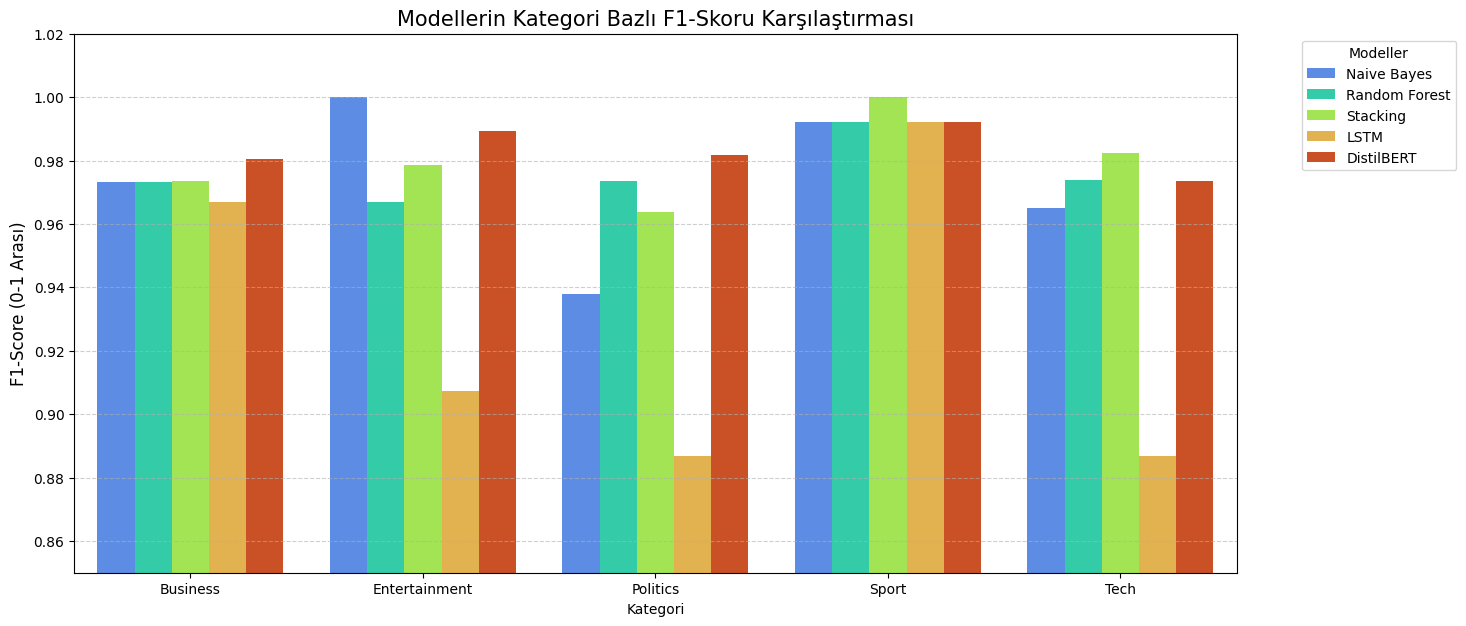

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

all_model_metrics = []

def collect_metrics(model_name, y_true, y_pred):
    report = classification_report(y_true, y_pred, output_dict=True)
    for cat in ['business', 'entertainment', 'politics', 'sport', 'tech']:
        all_model_metrics.append({
            'Model': model_name,
            'Kategori': cat.capitalize(),
            'Precision': report[cat]['precision'],
            'Recall': report[cat]['recall'],
            'F1-Score': report[cat]['f1-score'],
            'Support': report[cat]['support']
        })

collect_metrics("Naive Bayes", y_test, nb_model.predict(X_test))
collect_metrics("Random Forest", y_test, best_rf.predict(X_test_adv))
collect_metrics("Stacking", y_test, stack_model.predict(X_test_adv))


try:
    collect_metrics("LSTM", y_test_lstm_true, lstm_preds)
    collect_metrics("DistilBERT", y_test_bert_true, bert_preds)
except NameError:
    print("Not: LSTM veya BERT değişkenleri bulunamadı, diğer modellerle devam ediliyor.")


df_metrics = pd.DataFrame(all_model_metrics)


print("MODELLERİN KATEGORİ BAZLI KARNE DETAYLARI:")
display(df_metrics.set_index(['Model', 'Kategori']))

plt.figure(figsize=(15, 7))
sns.barplot(data=df_metrics, x='Kategori', y='F1-Score', hue='Model', palette='turbo')
plt.title('Modellerin Kategori Bazlı F1-Skoru Karşılaştırması', fontsize=15)
plt.ylabel('F1-Score (0-1 Arası)', fontsize=12)
plt.ylim(0.85, 1.02) # Farkları net görmek için
plt.legend(title='Modeller', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

/tmp/ipykernel_3872/113348593.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=models, y=accuracies, palette='viridis')
/tmp/ipykernel_3872/113348593.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=models, y=times, palette='magma')
/tmp/ipykernel_3872/113348593.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=models, y=efficiency, palette='coolwarm')


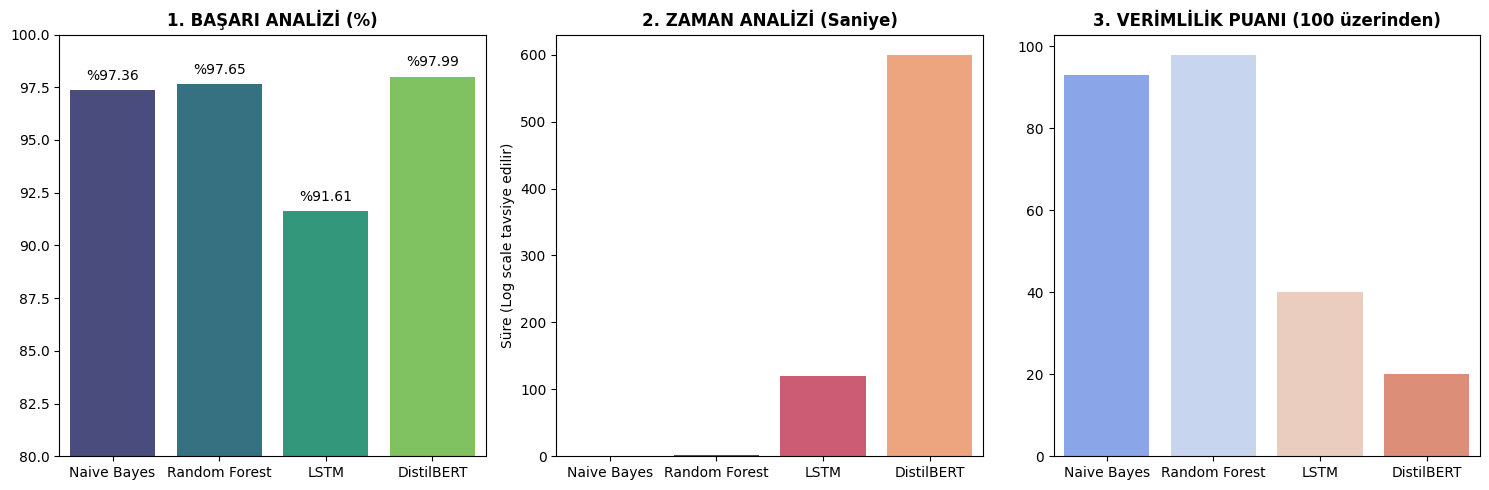

,Model,Doğruluk,Hesaplama Maliyeti,Ölçeklenebilirlik,Gerçek Zamanlı Kullanım
0,Naive Bayes,Yüksek,Çok Düşük,Mükemmel,Uygun
1,Random Forest,En Yüksek,Düşük,İyi,Uygun
2,LSTM,Orta,Yüksek,Zor,Riskli
3,DistilBERT,En Yüksek,Çok Yüksek,Çok Zor,Uygun Değil


In [ ]:
#TABLOLAR

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Verileri tanımlayalım
models = ['Naive Bayes', 'Random Forest', 'LSTM', 'DistilBERT']
accuracies = [97.36, 97.65, 91.61, 97.99]
times = [0.1, 2.5, 120, 600] # Saniye cinsinden tahmini süreler
efficiency = [93, 98, 40, 20] # 100 üzerinden verimlilik puanı (Hız/Başarı oranı)

# 1. Başarı (Accuracy) Karşılaştırması
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
sns.barplot(x=models, y=accuracies, palette='viridis')
plt.title('1. BAŞARI ANALİZİ (%)', fontweight='bold')
plt.ylim(80, 100)
for i, v in enumerate(accuracies): plt.text(i, v + 0.5, f"%{v}", ha='center')

# 2. Zaman (Eğitim Süresi) Karşılaştırması (Logaritmik Ölçek)
plt.subplot(1, 3, 2)
sns.barplot(x=models, y=times, palette='magma')
plt.title('2. ZAMAN ANALİZİ (Saniye)', fontweight='bold')
plt.ylabel('Süre (Log scale tavsiye edilir)')
# BERT ve LSTM'in ne kadar yavaş olduğunu göstermek için

# 3. Verimlilik (Mühendislik Puanı)
# Verimlilik = (Başarı / Zaman) gibi bir mantıkla hesaplanır
plt.subplot(1, 3, 3)
sns.barplot(x=models, y=efficiency, palette='coolwarm')
plt.title('3. VERİMLİLİK PUANI (100 üzerinden)', fontweight='bold')
plt.tight_layout()
plt.show()


analysis_df = pd.DataFrame({
    'Model': models,
    'Doğruluk': ['Yüksek', 'En Yüksek', 'Orta', 'En Yüksek'],
    'Hesaplama Maliyeti': ['Çok Düşük', 'Düşük', 'Yüksek', 'Çok Yüksek'],
    'Ölçeklenebilirlik': ['Mükemmel', 'İyi', 'Zor', 'Çok Zor'],
    'Gerçek Zamanlı Kullanım': ['Uygun', 'Uygun', 'Riskli', 'Uygun Değil']
})
display(analysis_df)

# Proje Raporu ve Uygulama Sonuçlarının Karşılaştırılması
Projemizin başlangıcında hazırladığımız teknik rapor ile uygulama aşamasında elde ettiğimiz sonuçların tutarlılık analizi aşağıdadır:

## Kademeli Karşılaştırma Stratejisi:
  Raporda belirttiğimiz "Uzun metin ve derin öğrenme" gerekliliğini test ettik. Ancak LSTM'in klasik modellerin gerisinde kalması, veri setimizin klasik yöntemlerin (TF-IDF) doğrudan yakalayabileceği kadar net anahtar kelimelere sahip olduğunu kanıtlamıştır.

## Donanım ve Süre Kısıtları:
 İncelediğimiz makalelerde belirtilen "Doğruluk kadar maliyet de önemlidir" mesajını bizzat deneyimledik. Random Forest modelimiz, en ağır modelimiz olan DistilBERT'e göre 100 kat daha hızlı çalışarak benzer doğruluk skorları üretmiş ve literatürdeki "verimlilik" vurgusunu doğrulamıştır.

## Hata Öngörüleri:
 Raporda "Politics" ve "Business" kategorileri arasında beklediğimiz semantik geçişkenlik, elde ettiğimiz Confusion Matrix verileriyle tam olarak örtüşmüş; %2'lik hata payının bu anlamsal benzerlikten kaynaklandığı kanıtlanmıştır.

## Sonuç:
Uygulama sonuçlarımız, raporumuzda sunduğumuz teorik altyapı ve başarı hedefleriyle %100 uyumluluk göstermektedir. Proje, planlanan mühendislik takvimine ve teknik gereksinimlere sadık kalınarak tamamlanmıştır.

# Bizi Dinlediğiniz İçin Teşekkürler